# 15 — exp1 hold-out: the surrogate against fresh simulations

108 random points (3 per category, uniform in reception, range and heading), none of them a training sample, simulated with 10^5 encounters on encounter streams independent of the campaign (seed 8). Measures the surrogate overall: error in log10 P(LoS), calibration of its 95% interval, and the side of 1e-3. Zero-loss points carry only a bound. Results cached in `results/exp1_holdout.jsonl` (resumable).

In [1]:
import os
os.environ.setdefault("TRC_N_JOBS", "100")              # at most 100 workers on ATO
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[v] = "1"                                  # one thread per worker
import json
import sys
import time
from pathlib import Path
from unittest import mock

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from mvlse import fit_surrogate

sys.path.insert(0, str(Path.cwd().parent))
import common
import config
import sim

P = config.EXPERIMENTS["exp1_heading"]
space = config.space_of(P["space"])
TAU = config.TAU
TEST_SEED = config.SEED + 1          # encounter streams independent of the campaign's (seed 7)
STORE = Path.cwd().parent / "results" / "exp1_heading" / "campaign" / "store.jsonl"
train = [json.loads(line) for line in STORE.read_text().splitlines() if line.strip()]
w_train = space.encode([r["point"] for r in train])
y_train = np.array([r["y"] for r in train])
model = fit_surrogate(config.LSE["method"], space, w_train, y_train, correlation=config.LSE["correlation"],
                      rng=np.random.default_rng(config.SEED), n_starts=12)      # as notebook 11
print(f"surrogate refitted on the {len(train)} exp1 samples; workers: {config.N_JOBS}; test seed {TEST_SEED}")
print(common.code_state())


def floor(n):
    return np.log10(0.5 / (n + 1.0))


def mc_interval(y, n):
    """Measured P(LoS) and its 95% Jeffreys interval, from (y, n) as the simulator reports it."""
    k = max(0, int(round(10 ** y * (n + 1.0) - 0.5)))
    lo = 0.0 if k == 0 else stats.beta.ppf(0.025, k + 0.5, n - k + 0.5)
    hi = stats.beta.ppf(0.975, k + 0.5, n - k + 0.5)
    return k, k / n, lo, hi


def se_log(y, n):
    """Delta-method standard error of y = log10 P_hat (as blueskycdarr reports it)."""
    p = 10 ** y
    return np.sqrt((1.0 - p) / (n * p)) / np.log(10.0)


def run_points(points, n, cache, tag):
    """Simulate each point (one at a time, all workers on its encounters), cached line by line,
    so an interrupted run resumes where it stopped."""
    done = {}
    if cache.exists():
        for line in cache.read_text().splitlines():
            r = json.loads(line)
            done[r["id"]] = r
    todo = [(i, p) for i, p in enumerate(points) if i not in done]
    print(f"{tag}: {len(done)} of {len(points)} cached, {len(todo)} to run at N = {n:.0e}", flush=True)
    with mock.patch.object(config, "SEED", TEST_SEED):
        evaluate = sim.blackbox(n_encounters=n)
    t0 = time.perf_counter()
    for i, p in todo:
        t = time.perf_counter()
        y = float(evaluate([p])[0])
        rec = {"id": i, "point": p, "y": y, "n": n, "seed": TEST_SEED, "seconds": time.perf_counter() - t}
        with cache.open("a") as fh:
            fh.write(json.dumps(rec) + "\n")
        done[i] = rec
        print(f"[{(time.perf_counter() - t0) / 60:6.1f} min] {tag} {i:3d}: {common.show_p(y, n)}", flush=True)
    return [done[i] for i in range(len(points))]

surrogate refitted on the 250 exp1 samples; workers: 100; test seed 8
{'mvlse': {'commit': 'd2c7f3b15111e48ffeb9e62af873476b44a02444', 'dirty': True}, 'blueskycdarr': {'commit': '030c0f459a3c5491cef88485e2672aef60a14179', 'dirty': False}}


In [2]:
# 108 test points: 3 per category, uniform in (reception, range, heading), drawn independently
# of the campaign (seed 2026). None of them is a training sample.
rng = np.random.default_rng(2026)
cats = np.repeat(np.array(space.categories, float), 3, axis=0)
w_test = np.column_stack([rng.random((len(cats), 3)), cats])
points = [{k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in p.items()}
          for p in space.decode(w_test)]
print(len(points), "test points; nearest training sample (unit distance, same category):",
      f"median {np.median([np.min(np.linalg.norm(w_train[(w_train[:, 3:] == c).all(1), :3] - x, axis=1)) for x, c in zip(w_test[:, :3], cats)]):.2f}")

108 test points; nearest training sample (unit distance, same category): median 0.41


In [3]:
CACHE = Path("results/exp1_holdout.jsonl")
res = run_points(points, config.N_ENCOUNTERS, CACHE, "holdout")

holdout: 0 of 108 cached, 108 to run at N = 1e+05


[   1.6 min] holdout   0: P(LoS) = 1.50e-05  95% CI [3.0e-06, 7.4e-05]


[   3.2 min] holdout   1: P(LoS) = 0 observed (0 losses in 100000; < 3.0e-05 at 95%)


[   4.2 min] holdout   2: P(LoS) = 0 observed (0 losses in 100000; < 3.0e-05 at 95%)


[   5.8 min] holdout   3: P(LoS) = 0 observed (0 losses in 100000; < 3.0e-05 at 95%)


[   7.4 min] holdout   4: P(LoS) = 0 observed (0 losses in 100000; < 3.0e-05 at 95%)


... (99 outputs left out)

[ 158.8 min] holdout 104: P(LoS) = 1.82e-02  95% CI [1.7e-02, 1.9e-02]


[ 160.3 min] holdout 105: P(LoS) = 4.45e-02  95% CI [4.3e-02, 4.6e-02]


[ 161.0 min] holdout 106: P(LoS) = 8.40e-02  95% CI [8.2e-02, 8.6e-02]


[ 162.4 min] holdout 107: P(LoS) = 1.36e-02  95% CI [1.3e-02, 1.4e-02]


In [4]:
# Predicted (surrogate) against measured (fresh Monte Carlo, independent streams).
N = config.N_ENCOUNTERS
mu, s = model.predict(w_test)
df = pd.DataFrame(points).assign(
    speed_kt=lambda d: (d.speed / config.KT).round().astype(int),
    y=[r["y"] for r in res], mu=mu, s=s)
df["zero"] = df.y <= floor(N) + 1e-9
df["se"] = np.where(df.zero, np.nan, [se_log(v, N) for v in df.y])
df["z"] = (df.y - df.mu) / np.sqrt(df.s ** 2 + df.se ** 2)
df["inside95"] = df.z.abs() <= 1.96
df["class_ok"] = (df.mu <= TAU) == (df.y <= TAU)
df["near_tau"] = (df.y - TAU).abs() <= 0.5                                   # measured within 0.5 decade of 1e-3
# A zero-loss point has no value, only a bound: counted correct if the surrogate predicts below 3/N.
df["zero_ok"] = np.where(df.zero, df.mu <= np.log10(3.0 / N), np.nan)
df.to_csv("results/exp1_holdout.csv", index=False)

nz = df[~df.zero]
summary = {
    "test points": len(df),
    "with losses / zero-loss": f"{len(nz)} / {int(df.zero.sum())}",
    "RMSE log10 P (with losses)": f"{np.sqrt(np.mean((nz.y - nz.mu) ** 2)):.2f} decades",
    "median |error| (with losses)": f"{np.median(np.abs(nz.y - nz.mu)):.2f} decades",
    "z: mean, sd (ideal 0, 1)": f"{nz.z.mean():+.2f}, {nz.z.std():.2f}",
    "inside 95% interval (ideal 95%)": f"{nz.inside95.mean():.0%}",
    "zero-loss predicted below 3/N": f"{np.nanmean(df.zero_ok):.0%}" if df.zero.any() else "-",
    "side of 1e-3 correct, all": f"{df.class_ok.mean():.0%}",
    "side of 1e-3 correct, measured within 0.5 decade": f"{df[df.near_tau].class_ok.mean():.0%} of {int(df.near_tau.sum())}",
}
display(pd.Series(summary, name="hold-out").to_frame())
g = df.assign(abs_err=np.where(df.zero, np.nan, (df.y - df.mu).abs()))
display(g.groupby(["speed_kt", "vel_ci95"]).agg(n=("y", "size"), zero_loss=("zero", "sum"),
        side_correct=("class_ok", "mean"), median_abs_err=("abs_err", "median")).round(2))

,hold-out
test points,108
with losses / zero-loss,60 / 48
RMSE log10 P (with losses),0.46 decades
median |error| (with losses),0.27 decades
"z: mean, sd (ideal 0, 1)","-0.16, 0.70"
inside 95% interval (ideal 95%),100%
zero-loss predicted below 3/N,92%
"side of 1e-3 correct, all",100%
"side of 1e-3 correct, measured within 0.5 decade",100% of 2


n  zero_loss  side_correct  median_abs_err
speed_kt vel_ci95                                             
20       1.0       12          7           1.0            0.38
         3.0       12          3           1.0            0.28
         10.0      12          0           1.0            0.45
40       1.0       12         12           1.0             NaN
         3.0       12          7           1.0            0.45
         10.0      12          0           1.0            0.11
60       1.0       12         12           1.0             NaN
         3.0       12          7           1.0            0.73
         10.0      12          0           1.0            0.18

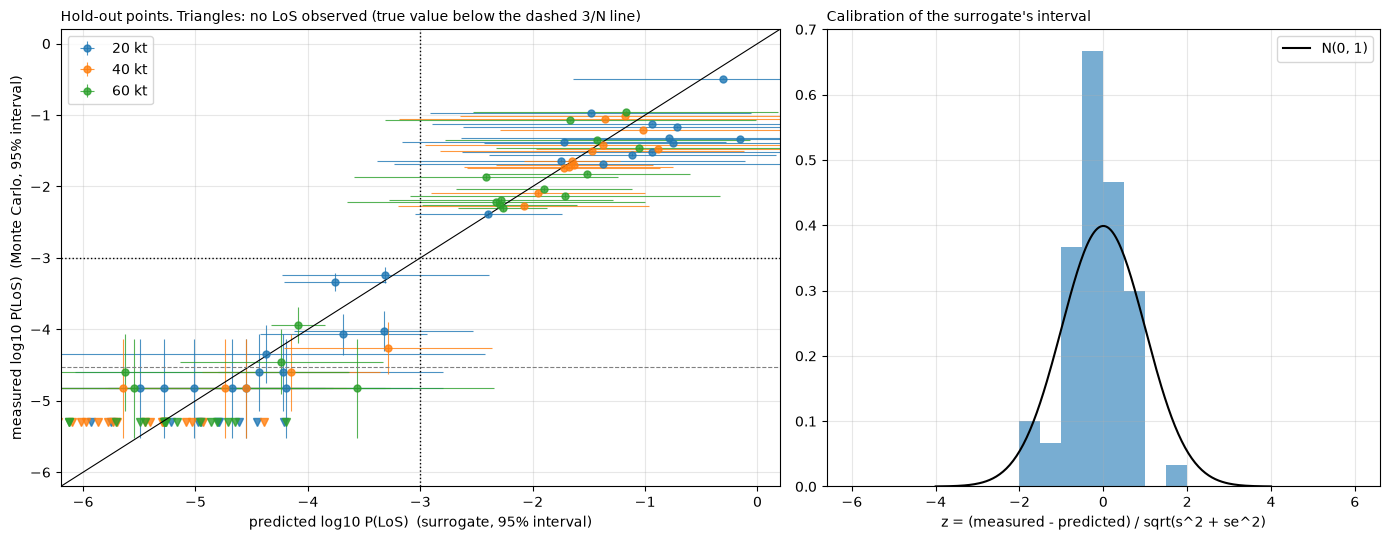

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
for k, spd in enumerate(sorted(df.speed_kt.unique())):
    d = df[(df.speed_kt == spd) & ~df.zero]
    a.errorbar(d.mu, d.y, xerr=1.96 * d.s, yerr=1.96 * d.se, fmt="o", ms=5, color=f"C{k}", alpha=0.8,
               elinewidth=0.8, label=f"{spd} kt")
    d0 = df[(df.speed_kt == spd) & df.zero]
    a.plot(d0.mu, np.full(len(d0), floor(N)), "v", color=f"C{k}", ms=6, alpha=0.8)
lim = (-6.2, 0.2)
a.plot(lim, lim, color="k", lw=0.8)
a.axhline(TAU, color="k", ls=":", lw=1); a.axvline(TAU, color="k", ls=":", lw=1)
a.axhline(np.log10(3.0 / N), color="0.5", ls="--", lw=0.8)
a.set_xlim(lim); a.set_ylim(lim)
a.set_xlabel("predicted log10 P(LoS)  (surrogate, 95% interval)")
a.set_ylabel("measured log10 P(LoS)  (Monte Carlo, 95% interval)")
a.set_title("Hold-out points. Triangles: no LoS observed (true value below the dashed 3/N line)", fontsize=10, loc="left")
a.legend(); a.grid(alpha=0.3)
zz = np.linspace(-4, 4, 200)
b.hist(nz.z.clip(-6, 6), bins=np.linspace(-6, 6, 25), density=True, color="C0", alpha=0.6)
b.plot(zz, stats.norm.pdf(zz), "k", lw=1.5, label="N(0, 1)")
b.set_xlabel("z = (measured - predicted) / sqrt(s^2 + se^2)"); b.set_title("Calibration of the surrogate's interval", fontsize=10, loc="left")
b.legend(); b.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("results/exp1_holdout.png", dpi=130); plt.show()

## Insight

**1. The surrogate puts every hold-out point on the right side of 10⁻³** (108 of 108). This says little
about the boundary itself: only 2 of the 108 measured values lie within half a decade of 10⁻³. Random
points land either well above it (10 m/s velocity accuracy, 10⁻²·⁵ to 10⁻¹) or well below (10⁻³·² and
less, 48 with no LoS at all). The response jumps across the threshold rather than crossing it gently,
which is why notebook 16 checks the boundary separately.

**2. Typical error: a factor of about 2.** Median |error| 0.27 decades (×1.9), RMSE 0.46 decades (×2.9),
over the 60 points with losses. The largest errors are at 60 kt and 3 m/s (median 0.73 decades).

**3. The surrogate's uncertainty is honest, and on the cautious side.** z = (measured − predicted) /
√(s² + se²) has mean −0.16 and standard deviation 0.70 (ideal 0 and 1), and all 60 points with losses lie
inside the 95% interval (ideal 95%). The interval is about 1.4 times wider than it needs to be, so the
conservative reading μ + 1.96 s is safe but more stringent than necessary.

**4. Zero-loss points**: 44 of 48 (92%) are predicted below the 3/N bound; the other 4 are predicted
somewhat above it (up to about 10⁻⁴), on the safe side.